# Night Shift ML: clustering the hunting situations (K-Means, DBSCAN, Agglomerative)

<a href="https://colab.research.google.com/github/Jesu0809/machine-learning-final-project/blob/main/training/notebooks/clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Machine Learning, Universidad de Cundinamarca. Jesús David Nuncira Ortiz and Miguel Moreno Arenas.**

The trained network that drives Pockets reads 100 numbers per decision. In the playtest studio (the web information
system) every behaviour report and every inference stores one of these situations. Here we use **unsupervised
learning** to find which *kinds of hunting moments* exist, with three clustering algorithms:

1. **K-Means** (centroids), 2. **DBSCAN** (density), 3. **Agglomerative clustering** (hierarchy, Ward linkage).

We compare them with internal metrics (silhouette, Davies-Bouldin, Calinski-Harabasz) and with external labels the
clusters never saw (Pockets' room and the decision of the network), and we interpret the clusters to decide how the
system can use them.

## 1. Setup and data

In [1]:
import os, urllib.request, random, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # spurious macOS Accelerate warnings; results are exact
BASE = "https://raw.githubusercontent.com/Jesu0809/machine-learning-final-project/main/web/"
os.makedirs("data", exist_ok=True)
for remote, local in [("freddy_brain.py", "freddy_brain.py"), ("data/FreddyPolicy.bytes", "data/FreddyPolicy.bytes")]:
    if not os.path.exists(local):
        urllib.request.urlretrieve(BASE + remote, local)

import numpy as np
import matplotlib.pyplot as plt
import freddy_brain as brain
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

def random_situation(rng):
    rooms = brain.ROOM_COUNT
    s = {"freddy_room": rng.randrange(rooms), "noises": {}, "night_progress": round(rng.random(), 2),
         "objectives": round(rng.random() * 0.8, 2), "sense_ready": rng.random() < 0.6}
    for _ in range(rng.choice((0, 0, 1, 1, 2))):
        s["noises"][str(rng.randrange(rooms))] = rng.choice((1, 2, 3))
    if rng.random() < 0.4:
        s["last_seen_room"] = rng.randrange(rooms); s["seconds_since_seen"] = rng.randrange(5, 200)
    s["rooms_not_checked"] = sorted(rng.sample(range(rooms), rng.randrange(3, rooms)))
    if rng.random() < 0.15:
        s["sees_player"] = True
    return s

rng = random.Random(2026)
situations = [random_situation(rng) for _ in range(3000)]
X = np.array([brain.observations(s) for s in situations])
action = np.array([brain.decide(s)["chosen"]["index"] for s in situations])
room = np.array([s["freddy_room"] for s in situations])
def kind_of(a, r):
    return "Sense" if a == brain.SENSE else "Search a spot" if a >= brain.ROOM_COUNT else "Stay and listen" if a == r else "Move to a room"
kind = np.array([kind_of(a, r) for a, r in zip(action, room)])
print(X.shape, {k: int((kind == k).sum()) for k in np.unique(kind)})

(3000, 100) {np.str_('Move to a room'): 2249, np.str_('Search a spot'): 99, np.str_('Sense'): 583, np.str_('Stay and listen'): 69}


### Which features to cluster on

If we cluster all 100 inputs, the strongest signal is Pockets' own room (a one-hot block), and the clusters simply
rediscover the 13 rooms. That is checked in section 5. To find *moments of the hunt* we build a compact description
of the clues instead, the same information a designer reads in a report:

In [2]:
R = brain.ROOM_COUNT
noise = X[:, brain.NOISE:brain.NOISE + R]
F = np.column_stack([
    noise.max(axis=1),                                     # loudest remembered noise (0-1)
    (noise > 0).sum(axis=1) / R,                           # share of rooms with a noise
    X[:, brain.LAST_SEEN:brain.LAST_SEEN + R].max(axis=1), # has a sighting
    1 - X[:, brain.SINCE_SEEN],                            # freshness of the sighting (1 = just now)
    X[:, brain.SEEN_NOW],                                  # sees the player now
    (X[:, brain.VISITED:brain.VISITED + R] == 1).mean(axis=1),  # share of rooms unchecked for long
    X[:, brain.OBJECTIVES_INDEX],                          # objectives done
    X[:, brain.PROGRESS],                                  # night progress
    X[:, brain.SENSE_READY],                               # sense ready
])
FEATURES = ["loudest noise", "rooms with noise", "has sighting", "sighting freshness", "sees now",
            "unchecked share", "objectives", "night progress", "sense ready"]
from sklearn.preprocessing import StandardScaler
Fs = StandardScaler().fit_transform(F)   # unsupervised: no train/test split, every feature on the same scale
print(F.shape)

(3000, 9)


## 2. K-Means: choosing k

k= 2  inertia=  21928.6  silhouette=0.196
k= 3  inertia=  19273.3  silhouette=0.163


k= 4  inertia=  17411.8  silhouette=0.171
k= 5  inertia=  15867.2  silhouette=0.183


k= 6  inertia=  14914.2  silhouette=0.169
k= 7  inertia=  14286.2  silhouette=0.175


k= 8  inertia=  13956.2  silhouette=0.150
k= 9  inertia=  13361.1  silhouette=0.148


k=10  inertia=  12872.9  silhouette=0.159


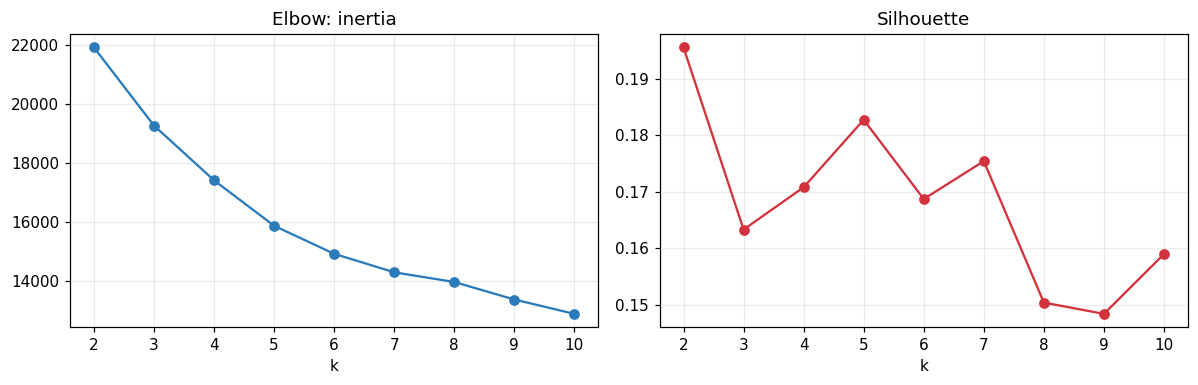

In [3]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Fs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Fs, km.labels_))
    print(f"k={k:2d}  inertia={km.inertia_:9.1f}  silhouette={sil[-1]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(ks), inertia, marker="o", color="#2b7bba"); ax[0].set_title("Elbow: inertia"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, marker="o", color="#d1323b"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

In [4]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Fs)
labels_km = kmeans.labels_
print("chosen k =", K)

chosen k = 4


## 3. DBSCAN: choosing eps with the k-distance curve

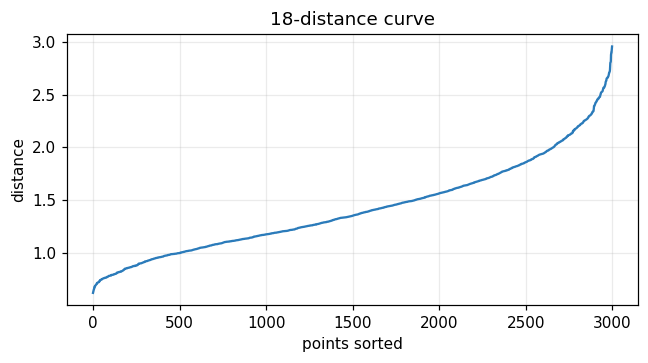

eps=0.9: 5 clusters, noise 83.4%, silhouette (without noise) 0.195
eps=1.1: 8 clusters, noise 56.7%, silhouette (without noise) 0.211


eps=1.3: 12 clusters, noise 33.3%, silhouette (without noise) 0.195


eps=1.5: 12 clusters, noise 18.1%, silhouette (without noise) 0.186


eps=1.8: 7 clusters, noise 7.3%, silhouette (without noise) 0.171


In [5]:
from sklearn.neighbors import NearestNeighbors
min_samples = 18   # about 2 x the number of features
d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Fs).kneighbors(Fs)
kd = np.sort(d[:, -1])
plt.figure(figsize=(6, 3.4)); plt.plot(kd, color="#2b7bba"); plt.title(f"{min_samples}-distance curve")
plt.xlabel("points sorted"); plt.ylabel("distance"); plt.tight_layout(); plt.show()
for eps in (0.9, 1.1, 1.3, 1.5, 1.8):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Fs)
    n = len(set(lab) - {-1}); noise_share = (lab == -1).mean()
    s = silhouette_score(Fs[lab != -1], lab[lab != -1]) if n > 1 else float("nan")
    print(f"eps={eps:.1f}: {n} clusters, noise {noise_share:.1%}, silhouette (without noise) {s:.3f}")

In [6]:
EPS = 1.3
labels_db = DBSCAN(eps=EPS, min_samples=min_samples).fit_predict(Fs)
print("DBSCAN clusters:", len(set(labels_db) - {-1}), "| noise points:", int((labels_db == -1).sum()))

DBSCAN clusters: 12 | noise points: 1000


## 4. Agglomerative clustering (Ward)

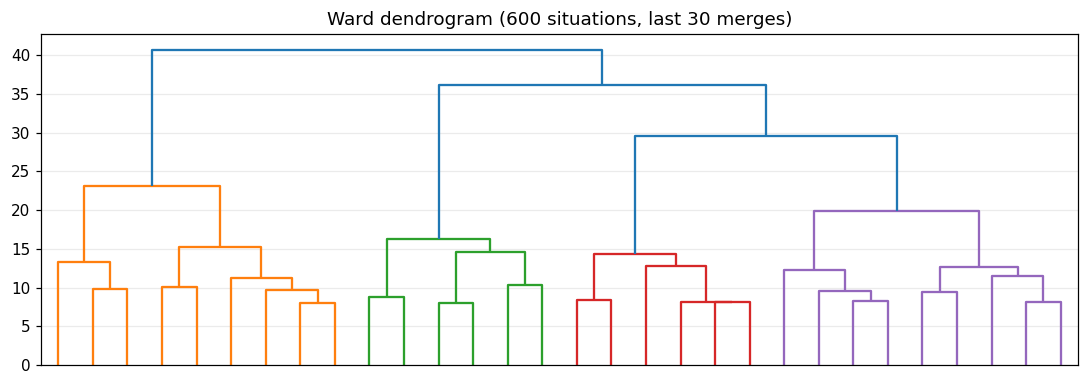

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram
sample = np.random.RandomState(0).choice(len(Fs), 600, replace=False)
Z = linkage(Fs[sample], method="ward")
plt.figure(figsize=(10, 3.6)); dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=Z[-K + 1, 2])
plt.title("Ward dendrogram (600 situations, last 30 merges)"); plt.tight_layout(); plt.show()
labels_ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Fs)

## 5. Comparison of the three algorithms

In [8]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
def scores(name, lab):
    m = lab != -1
    n = len(set(lab[m]))
    return {"algorithm": name, "clusters": n, "noise": f"{(~m).mean():.1%}",
            "silhouette": round(silhouette_score(Fs[m], lab[m]), 3),
            "davies_bouldin": round(davies_bouldin_score(Fs[m], lab[m]), 3),
            "calinski_harabasz": round(calinski_harabasz_score(Fs[m], lab[m]), 1),
            "NMI_vs_decision": round(normalized_mutual_info_score(kind[m], lab[m]), 3),
            "NMI_vs_room": round(normalized_mutual_info_score(room[m], lab[m]), 3)}
table = [scores("K-Means (k=4)", labels_km), scores(f"DBSCAN (eps={EPS})", labels_db), scores("Agglomerative Ward (k=4)", labels_ag)]
for row in table:
    print(row)
km_all = KMeans(n_clusters=13, n_init=10, random_state=0).fit_predict(X)
print("K-Means on all 100 inputs with k=13: ARI vs Pockets' room =", round(adjusted_rand_score(room, km_all), 3))

{'algorithm': 'K-Means (k=4)', 'clusters': 4, 'noise': '0.0%', 'silhouette': 0.171, 'davies_bouldin': 1.664, 'calinski_harabasz': 549.9, 'NMI_vs_decision': 0.031, 'NMI_vs_room': 0.002}
{'algorithm': 'DBSCAN (eps=1.3)', 'clusters': 12, 'noise': '33.3%', 'silhouette': 0.195, 'davies_bouldin': 1.723, 'calinski_harabasz': 240.8, 'NMI_vs_decision': 0.124, 'NMI_vs_room': 0.014}
{'algorithm': 'Agglomerative Ward (k=4)', 'clusters': 4, 'noise': '0.0%', 'silhouette': 0.17, 'davies_bouldin': 1.673, 'calinski_harabasz': 548.1, 'NMI_vs_decision': 0.032, 'NMI_vs_room': 0.002}
K-Means on all 100 inputs with k=13: ARI vs Pockets' room = 1.0


## 6. Visualising the clusters (t-SNE of the 9 features)

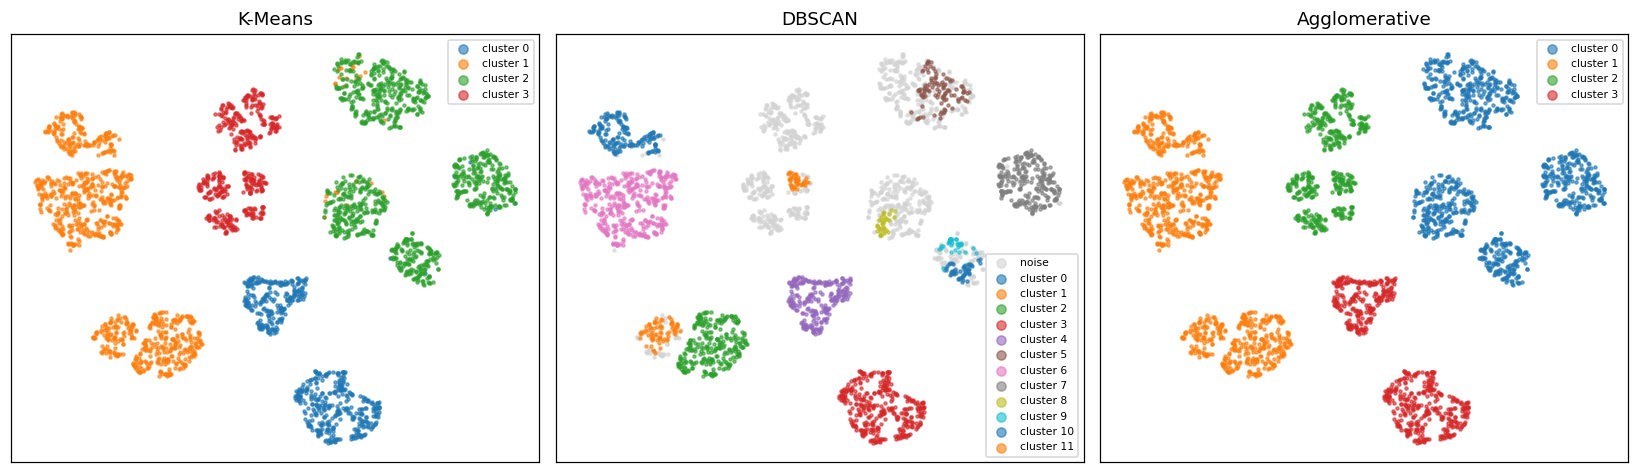

In [9]:
from sklearn.manifold import TSNE
emb = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=0).fit_transform(Fs)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (name, lab) in zip(axes, [("K-Means", labels_km), ("DBSCAN", labels_db), ("Agglomerative", labels_ag)]):
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color="lightgray" if c == -1 else None, label="noise" if c == -1 else f"cluster {c}")
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

## 7. What each K-Means cluster means

In [10]:
import pandas as pd
profile = pd.DataFrame(F, columns=FEATURES).groupby(labels_km).mean().round(2)
profile["size"] = np.bincount(labels_km)
decisions = pd.crosstab(labels_km, kind, normalize="index").round(2)
print(profile.to_string()); print(); print(decisions.to_string())

   loudest noise  rooms with noise  has sighting  sighting freshness  sees now  unchecked share  objectives  night progress  sense ready  size
0           0.00              0.00          0.01                0.00       0.0             0.54        0.40            0.51         0.59   591
1           0.72              0.10          0.03                0.00       0.0             0.52        0.39            0.50         0.60   980
2           0.40              0.06          1.00                0.53       0.0             0.53        0.40            0.49         0.60   991
3           0.42              0.06          0.45                0.23       1.0             0.53        0.40            0.48         0.59   438

col_0  Move to a room  Search a spot  Sense  Stay and listen
row_0                                                       
0                0.52           0.05   0.38             0.05
1                0.79           0.03   0.15             0.02
2                0.81           0.02   0

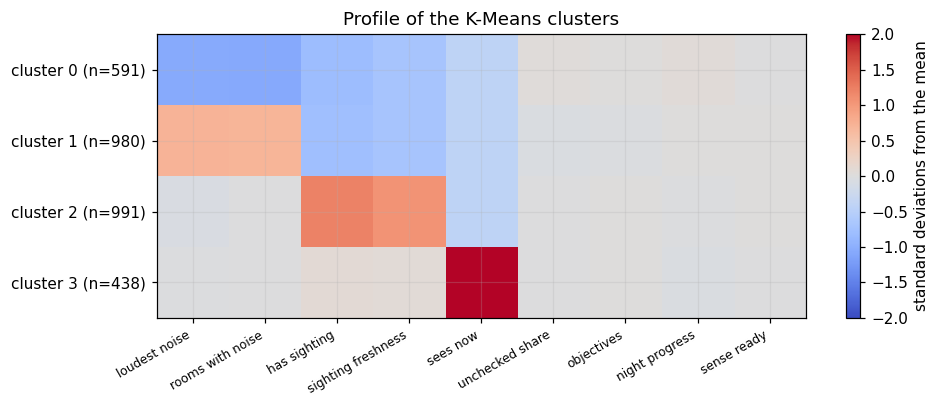

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
norm = (profile[FEATURES] - F.mean(axis=0)) / F.std(axis=0)
im = ax.imshow(norm.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(K)); ax.set_yticklabels([f"cluster {c} (n={n})" for c, n in enumerate(profile["size"])])
plt.colorbar(im, label="standard deviations from the mean"); ax.set_title("Profile of the K-Means clusters")
plt.tight_layout(); plt.show()

## 8. Conclusions

* **All 100 inputs:** K-Means with k = 13 reproduces Pockets' room exactly (ARI = 1.0). The one-hot room block dominates
  the distances, so clustering the raw inputs only tells us where he is.
* **Nine clue features, K-Means k = 4:** four readable moments of the hunt. Cluster 0 has no noise and no sighting
  (591 situations); cluster 1 has a loud remembered noise and no sighting (980); cluster 2 has a sighting, about half
  fresh (991); cluster 3 is when Pockets sees the player (438). The silhouette is highest at k = 2 (0.196), but k = 4
  is the elbow region and the only partition that separates the four kinds of clue, so it is the useful one.
* **Decisions inside the moments:** with no clue the network uses SENSE in 38% of the situations, against 13–15% when
  it has a noise or a sighting, where it moves 79–84% of the time. It feels for fear when it has nothing to follow:
  the clusters explain the policy without having seen its decisions.
* **Algorithm comparison:** K-Means and Ward agglomerative give almost the same partition (silhouette 0.171 / 0.170,
  Davies-Bouldin 1.66 / 1.67, Calinski-Harabasz 550 / 548). DBSCAN (eps = 1.3, min_samples = 18) finds 12 dense groups
  and leaves a third of the situations as noise; its clusters are slightly purer in decisions (NMI 0.124 against 0.03)
  but harder to name. The features are continuous and overlap, so every silhouette is modest: the moments are
  regions of a continuum, not separate islands.
* **Use in the system:** the playtest studio stores every situation it sends to the model. Labelling them with these
  four moments gives designers a readable summary of what playtesters report, and a change in the share of each
  moment among new inferences is an interpretable drift signal for the monitoring.
